Week2: Dataset Structuring and Validation

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [24]:
from pathlib import Path
base_dir = Path.cwd()

In [25]:
# Load Data
listing_filepath = r"20260929_w1_csv\20260929_listing_complete.csv"
sold_filepath = r"20260929_w1_csv\20260929_sold_complete.csv"

df_listings = pd.read_csv(listing_filepath)
df_sold = pd.read_csv(sold_filepath)

C:\Users\elizm\AppData\Local\Temp\ipykernel_15788\2316218107.py:5: DtypeWarning: Columns (5: ListAgentEmail, 46: BuyerAgencyCompensationType) have mixed types. Specify dtype option on import or set low_memory=False.
  df_listings = pd.read_csv(listing_filepath)
C:\Users\elizm\AppData\Local\Temp\ipykernel_15788\2316218107.py:6: DtypeWarning: Columns (10: ListAgentEmail, 48: BuyerAgencyCompensationType, 81: BuyerAgentAOR, 82: ListAgentAOR, 83: OriginatingSystemName, 84: OriginatingSystemSubName, 85: latfilled, 86: lonfilled) have mixed types. Specify dtype option on import or set low_memory=False.
  df_sold = pd.read_csv(sold_filepath)


Part 1: Dataset Understanding
•	Identify number of rows and columns
•	Review column data types
•	Identify high-missing columns
•	Separate market analysis fields from metadata fields

In [26]:
# Shape
print("# of rows | # of columns")
print(df_listings.shape[0],"   |", df_listings.shape[1])
print(df_sold.shape[0],"   |", df_sold.shape[1])

# of rows | # of columns
1022560    | 87
734352    | 87


In [27]:
# Data Types
listing_dtypes = df_listings.dtypes.to_frame('Data Type')
listing_dtypes.insert(0, 'Column Name', listing_dtypes.index)
sold_dtypes = df_sold.dtypes.to_frame('Data Type')
sold_dtypes.insert(0, 'Column Name', sold_dtypes.index)

In [28]:
# Save Data Types to CSV
listing_dtypes.to_csv('listings_dtypes.csv', index=False)
sold_dtypes.to_csv('sold_dtypes.csv', index=False)

In [29]:
# Null Value Analysis
listing_null_counts = df_listings.isnull().sum().to_frame('Null Counts')
listing_null_counts.insert(1, 'Null Percentage', round(listing_null_counts['Null Counts'] / df_listings.shape[0] * 100, 2))
listing_null_counts.insert(0, 'Column Name', listing_null_counts.index)
sold_null_counts = df_sold.isnull().sum().to_frame('Null Counts')
sold_null_counts.insert(1, 'Null Percentage', round(sold_null_counts['Null Counts'] / df_sold.shape[0] * 100, 2))
sold_null_counts.insert(0, 'Column Name', sold_null_counts.index)

In [30]:
# Columns present in both files
COMMON_DROP = [
    # duplicate IDs (keeping ListingId as the key)
    "ListingKey", "ListingKeyNumeric",

    # agent PII / identifiers / provenance
    "ListAgentEmail", "ListAgentFullName", "ListAgentFirstName", "ListAgentLastName",
    "CoListAgentFirstName", "CoListAgentLastName",
    "BuyerAgentMlsId", "BuyerAgentFirstName", "BuyerAgentLastName",
    "CoBuyerAgentFirstName",
    "source", "BuyerOfficeAOR", "BusinessType",

    # redundant with kept columns
    "LotSizeArea", "LotSizeDimensions",   # keep LotSizeSquareFeet
    "BuildingAreaTotal", "AboveGradeFinishedArea",        # keep LivingArea
    "CoveredSpaces", "ParkingTotal", "AttachedGarageYN",  # keep GarageSpaces
    "FireplaceYN",                                        # keep FireplacesTotal
    "StreetNumberNumeric", "TaxYear",

    # likely all-NaN (float dtype on a text field)
    "ElementarySchoolDistrict", "MiddleOrJuniorSchoolDistrict",

    # high-cardinality, covered by lat/long, postal code, subdivision
    "ElementarySchool", "MiddleOrJuniorSchool", "HighSchool",
]

# Listings file only
LISTINGS_DROP = COMMON_DROP + [
    # duplicate columns created by a merge/concat (verify they match the originals first)
    "PropertyType.1", "ListAgentFirstName.1", "ListAgentLastName.1",
    "DaysOnMarket.1", "LivingArea.1", "Longitude.1", "Latitude.1",
    "ListPrice.1", "CloseDate.1", "BuyerOfficeName.1", "UnparsedAddress.1",
]

# Sold file only
SOLD_DROP = COMMON_DROP + [
    "OriginatingSystemName", "OriginatingSystemSubName",
    "BuyerAgentAOR", "ListAgentAOR",
    "latfilled", "lonfilled",   # coalesce into Latitude/Longitude first
    "Flooring",                 # free text; keep if you plan to parse it
]

In [31]:
# Filter out irrevelant columns
listings_filtered = df_listings.drop(columns=LISTINGS_DROP)
sold_filtered = df_sold.drop(columns=SOLD_DROP)

Part2: Missing Value Analysis
•	Calculate missing counts and percentages per column
•	Flag columns with >90% missing values
•	Decide which columns to drop vs. retain (keep core fields even if partially missing)

In [32]:
#find null percentages per row
listings_filtered_col = listings_filtered.columns.to_list()
sold_filtered_col = sold_filtered.columns.to_list()

listing_null_counts = listing_null_counts[listing_null_counts['Column Name'].isin(listings_filtered_col)]

sold_null_counts = sold_null_counts[sold_null_counts['Column Name'].isin(sold_filtered_col)]

listing_max_nulls = listing_null_counts[listing_null_counts['Null Percentage'] > 0].sort_values(by='Null Percentage', ascending=False)
sold_max_nulls = sold_null_counts[sold_null_counts['Null Percentage'] > 0].sort_values(by='Null Percentage', ascending=False)

<Axes: xlabel='Null Percentage', ylabel='Count'>

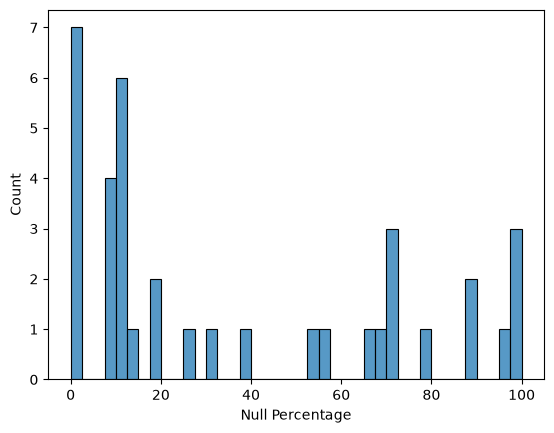

In [33]:
# Null Value Distribution
data = listing_max_nulls['Null Percentage']
sns.histplot(data=data, bins=40)

In [34]:
# Identify Columns with High Null Percentages
listing_nulls_90Plus = listing_null_counts[listing_null_counts['Null Percentage'] >= 90].sort_values(by='Null Percentage', ascending=False)
sold_nulls_90Plus = sold_null_counts[sold_null_counts['Null Percentage'] >= 90].sort_values(by='Null Percentage', ascending=False)

In [35]:
# Display Columns with High Null Percentages
print('columns with 90%+ nulls in listings:')
print(",".join(listing_nulls_90Plus['Column Name'].tolist()))
print()
print('columns with 90%+ nulls in sold listings:')
print(",".join(sold_nulls_90Plus['Column Name'].tolist()))

columns with 90%+ nulls in listings:
FireplacesTotal,BelowGradeFinishedArea,TaxAnnualAmount,BuilderName

columns with 90%+ nulls in sold listings:
FireplacesTotal,WaterfrontYN,TaxAnnualAmount,BelowGradeFinishedArea,BasementYN,BuilderName


In [36]:
listing_nulls_90Plus = listing_null_counts[listing_null_counts['Null Percentage'] >= 90].sort_values(by='Null Percentage', ascending=False)
sold_nulls_90Plus = sold_null_counts[sold_null_counts['Null Percentage'] >= 90].sort_values(by='Null Percentage', ascending=False)

In [37]:
# Drop Columns with High Null Percentages (80%+)
listing_data_final = listings_filtered.drop(columns=listing_nulls_90Plus['Column Name'].tolist())
sold_data_final = sold_filtered.drop(columns=sold_nulls_90Plus['Column Name'].tolist())


In [39]:
listing_data_final.to_csv(r'week_2_final_deliverables\listing_data.csv',index=False)
sold_data_final.to_csv(r'week_2_final_deliverables\sold_data.csv',index=False)

Part3: Numeric Distribution Review
Analyze the distribution of key numeric fields: ClosePrice, ListPrice, OriginalListPrice, LivingArea, LotSizeAcres, BedroomsTotal, BathroomsTotalInteger, DaysOnMarket, and YearBuilt. For each field, generate histograms, boxplots, and percentile summaries, and identify extreme outliers for later handling.

In [40]:
feature_list = ['ClosePrice', 'ListPrice', 'OriginalListPrice', 'LivingArea', 'LotSizeAcres', 'BedroomsTotal', 'BathroomsTotalInteger', 'DaysOnMarket','YearBuilt']

In [41]:
def numeric_summary_plots(df, output_dir=r"week_2_final_deliverables"):
    import os
    os.makedirs(output_dir, exist_ok=True)

    numeric_cols = df.select_dtypes(include=np.number).columns

    # Percentile summary
    percentile_summary = []

    for col in numeric_cols:
        s = pd.to_numeric(df[col], errors="coerce").dropna()

        if len(s) == 0:
            continue

        percentile_summary.append({
            "column": col,
            "count": len(s),
            "min": s.min(),
            "p1": s.quantile(0.01),
            "p5": s.quantile(0.05),
            "p25": s.quantile(0.25),
            "median": s.quantile(0.50),
            "p75": s.quantile(0.75),
            "p95": s.quantile(0.95),
            "p99": s.quantile(0.99),
            "max": s.max(),
            "mean": s.mean(),
            "std": s.std(),
            "missing_pct": df[col].isna().mean() * 100
        })

        # Histogram
        plt.figure(figsize=(8, 4))
        sns.histplot(s, bins=30)
        plt.title(f"Histogram: {col}")
        plt.tight_layout()
        plt.savefig(f"{output_dir}/{col}_hist.png")
        plt.close()

        # Boxplot
        plt.figure(figsize=(8, 2))
        sns.boxplot(x=s)
        plt.title(f"Boxplot: {col}")
        plt.tight_layout()
        plt.savefig(f"{output_dir}/{col}_box.png")
        plt.close()

    percentile_df = pd.DataFrame(percentile_summary)
    percentile_df.to_csv(
        f"{output_dir}/percentile_summary.csv",
        index=False
    )

    return percentile_df

In [42]:
target_dir = r"week_2_final_deliverables\sold_figures"
numeric_summary_plots(sold_data_final[feature_list], output_dir=target_dir)

,column,count,min,p1,p5,p25,median,p75,p95,p99,max,mean,std,missing_pct
0,ClosePrice,734344,0.0,1750.0,2650.0000,50000.00,630000.0000,1075000.0,2.500000e+06,5.000000e+06,9.895000e+08,877426.973902,5.200675e+06,0.001089
1,ListPrice,733245,0.0,1795.0,2700.0000,60000.00,629999.0000,1070000.0,2.499000e+06,5.000000e+06,1.700000e+08,844364.247802,1.305690e+06,0.150745
2,OriginalListPrice,732238,0.0,1800.0,2750.0000,64600.00,640000.0000,1095000.0,2.557150e+06,5.300000e+06,1.390000e+09,909977.922431,5.630366e+06,0.287873
3,LivingArea,683398,0.0,480.0,731.8500,1185.00,1582.0000,2156.0,3.545000e+03,5.483000e+03,9.090909e+08,3169.449572,1.099882e+06,6.938634
4,LotSizeAcres,666451,0.0,0.0,0.0283,0.12,0.1685,0.3,3.694500e+00,1.584965e+01,3.702600e+08,618.319168,4.537204e+05,9.246383
5,BedroomsTotal,686408,0.0,1.0,1.0000,2.00,3.0000,4.0,5.000000e+00,6.000000e+00,1.800000e+02,3.084979,1.404986e+00,6.528749
6,BathroomsTotalInteger,701185,0.0,0.0,1.0000,2.00,2.0000,3.0,4.000000e+00,6.000000e+00,3.353000e+03,2.455958,4.245082e+00,4.516499
7,DaysOnMarket,734352,-288.0,0.0,2.0000,9.00,22.0000,54.0,1.480000e+02,2.930000e+02,1.243000e+04,43.389463,6.954004e+01,0.000000
8,YearBuilt,704070,1776.0,1911.0,1927.0000,1960.00,1979.0000,1999.0,2.023000e+03,2.025000e+03,2.027000e+03,1978.194520,2.717409e+01,4.123636


In [43]:
target_dir = r"week_2_final_deliverables\listing_figures"
numeric_summary_plots(listing_data_final[feature_list], output_dir=target_dir)

,column,count,min,p1,p5,p25,median,p75,p95,p99,max,mean,std,missing_pct
0,ClosePrice,291999,0.0,1650.0,2450.0000,5100.0000,575000.0000,1.035000e+06,2425000.0,4.700000e+06,8.200000e+08,7.859270e+05,3.272687e+06,71.444316
1,ListPrice,1020067,0.0,1800.0,2800.0000,89999.0000,639000.0000,1.150000e+06,2995000.0,7.193680e+06,4.436503e+08,9.854401e+05,2.210050e+06,0.243800
2,OriginalListPrice,1018647,0.0,1800.0,2850.0000,90000.0000,641990.0000,1.159000e+06,2999888.0,7.495000e+06,1.749000e+09,1.055781e+06,6.573333e+06,0.382667
3,LivingArea,896160,0.0,460.0,719.0000,1184.0000,1603.0000,2.236000e+03,3900.0,6.745000e+03,9.090909e+08,2.951538e+03,9.604896e+05,12.361133
4,LotSizeAcres,926697,0.0,0.0,0.0295,0.1214,0.1722,3.885000e-01,5.0,2.591040e+01,3.702600e+08,4.652318e+02,3.847586e+05,9.374804
5,BedroomsTotal,900201,0.0,1.0,1.0000,2.0000,3.0000,4.000000e+00,5.0,7.000000e+00,1.490000e+02,3.138681e+00,1.711128e+00,11.965948
6,BathroomsTotalInteger,939540,0.0,0.0,1.0000,2.0000,2.0000,3.000000e+00,5.0,7.000000e+00,4.010300e+04,2.546359e+00,4.152209e+01,8.118839
7,DaysOnMarket,1022560,-58.0,0.0,0.0000,4.0000,10.0000,2.300000e+01,79.0,1.400000e+02,2.539000e+03,1.997188e+01,2.915375e+01,0.000000
8,YearBuilt,940523,1776.0,1910.0,1926.0000,1960.0000,1979.0000,2.001000e+03,2023.0,2.025000e+03,2.028000e+03,1.978463e+03,2.806229e+01,8.022708


Part 4: Findings
●	What is the Residential vs. other property type share?
●	What are the median and average close prices?
●	What does the Days on Market distribution look like?
●	What percentage of homes sold above vs. below list price?
●	Are there any apparent date consistency issues (e.g., close date before listing date)?
●	Which counties have the highest median prices?

In [ ]:
"""
EDA for listings and sold MLS data.

Answers:
  1. Residential vs. other property type share
  2. Median / average close prices
  3. Days on Market distribution
  4. % of homes sold above vs. below list price
  5. Date consistency issues
  6. Counties with the highest median prices

Run:  python market_eda.py
Edit LISTINGS_PATH / SOLD_PATH below. Only the columns needed are loaded.
NOTE: this is exploratory, so CloseDate / DaysOnMarket etc. are used here even
though they are excluded from modeling features (leakage).
"""

LISTINGS_PATH = "listings.csv"
SOLD_PATH = "sold.csv"

NEEDED_COLS = [
    "PropertyType", "PropertySubType", "CountyOrParish",
    "ClosePrice", "ListPrice", "OriginalListPrice", "DaysOnMarket",
    "ListingContractDate", "PurchaseContractDate", "CloseDate",
]
DATE_COLS = ["ListingContractDate", "PurchaseContractDate", "CloseDate"]
MIN_COUNTY_SALES = 30   # ignore counties with fewer rows when ranking
TOP_N_COUNTIES = 10


def load(path: str) -> pd.DataFrame:
    header = pd.read_csv(path, nrows=0).columns
    cols = [c for c in NEEDED_COLS if c in header]
    missing = sorted(set(NEEDED_COLS) - set(cols))
    if missing:
        print(f"  [warn] columns not found in {path}: {missing}")
    df = pd.read_csv(path, usecols=cols, low_memory=False)
    for c in DATE_COLS:
        if c in df:
            df[c] = pd.to_datetime(df[c], errors="coerce")
    for c in ["ClosePrice", "ListPrice", "OriginalListPrice", "DaysOnMarket"]:
        if c in df:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    return df


def section(title: str) -> None:
    print(f"\n--- {title} ---")


def property_type_share(df: pd.DataFrame) -> None:
    section("1. Residential vs. other property type share")
    if "PropertyType" not in df:
        print("PropertyType not available")
        return
    pt = df["PropertyType"].fillna("(missing)").str.strip()
    share = (pt.value_counts(normalize=True) * 100).round(2)
    print(pd.DataFrame({"count": pt.value_counts(), "pct": share}))
    is_res = pt.str.contains("residential", case=False)
    print(f"\nResidential: {is_res.mean() * 100:.2f}%  |  Other: {(~is_res).mean() * 100:.2f}%")
    if "PropertySubType" in df:
        print("\nTop PropertySubType values:")
        print(df["PropertySubType"].fillna("(missing)").value_counts().head(10))


def price_summary(df: pd.DataFrame) -> None:
    section("2. Median and average prices")
    rows = {}
    for col in ["ClosePrice", "ListPrice", "OriginalListPrice"]:
        if col in df:
            s = df[col].where(df[col] > 0).dropna()
            rows[col] = {
                "n": len(s), "median": s.median(), "mean": s.mean(),
                "min": s.min(), "p95": s.quantile(0.95), "max": s.max(),
            }
    if rows:
        print(pd.DataFrame(rows).T.round(0).to_string(float_format="{:,.0f}".format))
    else:
        print("No price columns available")


def dom_distribution(df: pd.DataFrame) -> None:
    section("3. Days on Market distribution")
    if "DaysOnMarket" not in df:
        print("DaysOnMarket not available")
        return
    dom = df["DaysOnMarket"].dropna()
    print(f"non-null: {len(dom):,} of {len(df):,}")
    print(f"negative: {(dom < 0).sum():,}  |  zero: {(dom == 0).sum():,}")
    dom = dom[dom >= 0]
    print(dom.describe(percentiles=[.1, .25, .5, .75, .9, .95, .99]).round(1))
    bins = [-1, 7, 14, 30, 60, 90, 180, 365, np.inf]
    labels = ["0-7", "8-14", "15-30", "31-60", "61-90", "91-180", "181-365", "365+"]
    buckets = pd.cut(dom, bins=bins, labels=labels).value_counts(sort=False)
    print("\nBuckets (days):")
    print(pd.DataFrame({"count": buckets, "pct": (buckets / buckets.sum() * 100).round(2)}))


def above_below_list(df: pd.DataFrame) -> None:
    section("4. Sold above vs. below list price")
    for ref in ["ListPrice", "OriginalListPrice"]:
        if "ClosePrice" not in df or ref not in df:
            continue
        d = df[(df["ClosePrice"] > 0) & (df[ref] > 0)]
        if d.empty:
            print(f"vs {ref}: no rows with both prices")
            continue
        diff = d["ClosePrice"] - d[ref]
        cat = np.select([diff > 0, diff < 0], ["above", "below"], default="at")
        pct = pd.Series(cat).value_counts(normalize=True).mul(100).round(2)
        ratio = (d["ClosePrice"] / d[ref])
        print(f"\nvs {ref} (n={len(d):,})")
        print(pct.to_string())
        print(f"median close/list ratio: {ratio.median():.4f}  |  mean: {ratio.mean():.4f}")


def date_consistency(df: pd.DataFrame) -> None:
    section("5. Date consistency checks")
    n = len(df)
    for c in DATE_COLS:
        if c in df:
            print(f"{c}: {df[c].isna().sum():,} null ({df[c].isna().mean() * 100:.1f}%)"
                  f", range {df[c].min()} to {df[c].max()}")

    checks = [
        ("CloseDate", "<", "ListingContractDate", "close before listing"),
        ("CloseDate", "<", "PurchaseContractDate", "close before purchase contract"),
        ("PurchaseContractDate", "<", "ListingContractDate", "purchase contract before listing"),
    ]
    print()
    for a, op, b, label in checks:
        if a in df and b in df:
            bad = (df[a] < df[b])
            print(f"{label}: {bad.sum():,} rows ({bad.sum() / n * 100:.2f}%)")

    if "CloseDate" in df:
        now = pd.Timestamp.today()
        print(f"close date in the future: {(df['CloseDate'] > now).sum():,}")
        print(f"close date before 2000: {(df['CloseDate'] < '2000-01-01').sum():,}")

    # DaysOnMarket should roughly match the gap between listing and purchase contract
    if {"DaysOnMarket", "ListingContractDate", "PurchaseContractDate"} <= set(df.columns):
        gap = (df["PurchaseContractDate"] - df["ListingContractDate"]).dt.days
        mismatch = (df["DaysOnMarket"] - gap).abs() > 7
        valid = gap.notna() & df["DaysOnMarket"].notna()
        print(f"DaysOnMarket differs from listing->contract gap by >7 days: "
              f"{mismatch[valid].sum():,} of {valid.sum():,} comparable rows")

    if "DaysOnMarket" in df:
        print(f"negative DaysOnMarket: {(df['DaysOnMarket'] < 0).sum():,}")


def top_counties(df: pd.DataFrame) -> None:
    section(f"6. Counties with the highest median price (min {MIN_COUNTY_SALES} rows)")
    if "CountyOrParish" not in df:
        print("CountyOrParish not available")
        return
    price_col = "ClosePrice" if "ClosePrice" in df and df["ClosePrice"].gt(0).sum() > 0 else "ListPrice"
    print(f"price column used: {price_col}")
    d = df[df[price_col] > 0]
    g = (d.groupby("CountyOrParish")[price_col]
           .agg(n="count", median="median", mean="mean")
           .query("n >= @MIN_COUNTY_SALES")
           .sort_values("median", ascending=False)
           .head(TOP_N_COUNTIES))
    print(g.round(0).to_string(float_format="{:,.0f}".format))


def run(name: str, path: str) -> None:
    print("=" * 70)
    print(f"{name.upper()}  ({path})")
    print("=" * 70)
    df = load(path)
    print(f"rows: {len(df):,}")
    property_type_share(df)
    price_summary(df)
    dom_distribution(df)
    above_below_list(df)
    date_consistency(df)
    top_counties(df)


if __name__ == "__main__":
    run("listings", r'week_2_final_deliverables\listing_data.csv')
    run("sold", r'week_2_final_deliverables\sold_data.csv')

======================================================================
LISTINGS  (week_2_final_deliverables\listing_data.csv)
======================================================================
rows: 1,022,560

--- 1. Residential vs. other property type share ---
                      count    pct
PropertyType                      
Residential          650190  63.58
ResidentialLease     212307  20.76
Land                  66384   6.49
ResidentialIncome     38112   3.73
ManufacturedInPark    29106   2.85
CommercialSale        14063   1.38
CommercialLease        9195   0.90
BusinessOpportunity    3203   0.31

Residential: 88.07%  |  Other: 11.93%

Top PropertySubType values:
PropertySubType
SingleFamilyResidence    575105
Condominium              175372
(missing)                123006
Townhouse                 53881
Apartment                 23458
Duplex                    20012
ManufacturedOnLand        10702
Quadruplex                 7214
Triplex                    6968
MixedUse                   6227
Name: count, dtype: int64

--- 2. Median and average prices ---
                          n  median      mean  min       p95           max
ClosePrice          291,979 575,000   785,981    1 2,425,000   820,000,000
ListPrice         1,020,059 639,000   985,448    0 2,995,000   443,650,265
OriginalListPrice 1,018,628 642,000 1,055,801    0 2,999,888 1,749,000,000

--- 3. Days on Market distribution ---
non-null: 1,022,560 of 1,022,560
negative: 41  |  zero: 117,427
count    1022519.0
mean          20.0
std           29.2
min            0.0
10%            0.0
25%            4.0
50%           10.0
75%           23.0
90%           51.0
95%           79.0
99%          140.0
max         2539.0
Name: DaysOnMarket, dtype: float64

Buckets (days):
               count    pct
DaysOnMarket               
0-7           393083  38.44
8-14          232851  22.77
15-30         215201  21.05
31-60          99865   9.77
61-90          43029   4.21
91-180         34604   3.38
181-365         3795   0.37
365+              91   0.01

--- 4. Sold above vs. below list price ---

vs ListPrice (n=291,687)
at       37.88
below    31.24
above    30.88
median close/list ratio: 1.0000  |  mean: 3.2786

vs OriginalListPrice (n=290,630)
below    40.40
above    30.05
at       29.55
median close/list ratio: 1.0000  |  mean: 28.5924

--- 5. Date consistency checks ---
ListingContractDate: 0 null (0.0%), range 2024-01-01 00:00:00 to 2026-09-29 00:00:00
PurchaseContractDate: 577,762 null (56.5%), range 1969-12-31 00:00:00 to 2028-02-27 00:00:00
CloseDate: 704,687 null (68.9%), range 2021-04-09 00:00:00 to 2030-04-16 00:00:00

close before listing: 169 rows (0.02%)
close before purchase contract: 367 rows (0.04%)
purchase contract before listing: 674 rows (0.07%)
close date in the future: 671
close date before 2000: 0
DaysOnMarket differs from listing->contract gap by >7 days: 58,487 of 444,798 comparable rows
negative DaysOnMarket: 41

--- 6. Counties with the highest median price (min 30 rows) ---
price column used: ClosePrice
                     n    median      mean
CountyOrParish                            
Santa Clara      10323 1,520,000 1,763,197
San Mateo         4873 1,470,000 1,808,904
Marin               82 1,188,500 1,370,927
San Francisco      669 1,170,000 1,259,427
Santa Cruz        1744 1,086,250 1,224,725
Alameda          11870 1,085,000 1,205,930
Monterey          1953   890,000 1,319,189
San Diego        32624   790,000 1,053,137
San Luis Obispo   3068   775,000   836,566
Contra Costa     11617   760,000   984,124
======================================================================
SOLD  (week_2_final_deliverables\sold_data.csv)
======================================================================
rows: 734,352

--- 1. Residential vs. other property type share ---
                      count    pct
PropertyType                      
Residential          493779  67.24
ResidentialLease     169052  23.02
Land                  23249   3.17
ResidentialIncome     19736   2.69
ManufacturedInPark    19697   2.68
CommercialSale         4542   0.62
CommercialLease        3825   0.52
BusinessOpportunity     472   0.06

Residential: 92.95%  |  Other: 7.05%

Top PropertySubType values:
PropertySubType
SingleFamilyResidence    449263
Condominium              127325
(missing)                 55184
Townhouse                 42490
Apartment                 17220
Duplex                    14118
ManufacturedOnLand         7424
Quadruplex                 4440
Triplex                    4414
StockCooperative           2415
Name: count, dtype: int64

--- 2. Median and average prices ---
                        n  median    mean  min       p95           max
ClosePrice        734,298 630,000 877,482    1 2,500,000   989,500,000
ListPrice         733,243 629,999 844,367    1 2,499,000   170,000,000
OriginalListPrice 732,232 640,000 909,985    1 2,557,450 1,390,000,000

--- 3. Days on Market distribution ---
non-null: 734,352 of 734,352
negative: 72  |  zero: 27,960
count    734280.0
mean         43.4
std          69.5
min           0.0
10%           4.0
25%           9.0
50%          22.0
75%          54.0
90%         104.0
95%         148.0
99%         293.0
max       12430.0
Name: DaysOnMarket, dtype: float64

Buckets (days):
               count    pct
DaysOnMarket               
0-7           156303  21.29
8-14          130752  17.81
15-30         146270  19.92
31-60         140477  19.13
61-90          68754   9.36
91-180         68529   9.33
181-365        19109   2.60
365+            4086   0.56

--- 4. Sold above vs. below list price ---

vs ListPrice (n=733,190)
below    38.60
at       30.94
above    30.45
median close/list ratio: 1.0000  |  mean: 2.4441

vs OriginalListPrice (n=732,178)
below    50.33
above    28.41
at       21.26
median close/list ratio: 0.9977  |  mean: 39.4456

--- 5. Date consistency checks ---
ListingContractDate: 86 null (0.0%), range 1984-08-28 00:00:00 to 2026-09-29 00:00:00
PurchaseContractDate: 14,874 null (2.0%), range 1923-11-16 00:00:00 to 2026-12-11 00:00:00
CloseDate: 0 null (0.0%), range 2024-01-01 00:00:00 to 2026-09-30 00:00:00

close before listing: 135 rows (0.02%)
close before purchase contract: 383 rows (0.05%)
purchase contract before listing: 666 rows (0.09%)
close date in the future: 0
close date before 2000: 0
DaysOnMarket differs from listing->contract gap by >7 days: 139,428 of 719,395 comparable rows
negative DaysOnMarket: 72

--- 6. Counties with the highest median price (min 30 rows) ---
price column used: ClosePrice
                     n    median      mean
CountyOrParish                            
Santa Clara      24536 1,485,000 1,745,671
San Mateo        10755 1,468,000 1,826,262
San Francisco     1531 1,108,000 1,199,351
Marin              209 1,080,000 1,259,866
Alameda          27128 1,050,000 1,254,573
Santa Cruz        4506 1,025,000 1,199,374
Monterey          5410   880,000 1,336,588
San Diego        78616   810,000 1,237,729
San Luis Obispo   9624   785,000   881,174
San Benito        1112   769,944   819,342

Final Deliverable
Submit a .py script documenting unique property types found, the filtering logic applied, and a null-count summary table. Include a missing value report flagging any columns above 90% null. Produce a numeric distribution summary (min, max, mean, median, percentiles) for ClosePrice, LivingArea, and DaysOnMarket. Save the filtered dataset as a new CSV.

In [ ]:
"""
Filter listings / sold data to residential records and profile the result.

For each dataset this script:
  1. Documents the unique PropertyType values found (with counts) and which are kept
  2. Applies the filters below, logging row counts after every step
  3. Produces a null-count summary table for ALL columns (pre-filter and post-filter)
  4. Flags columns that are more than NULL_FLAG_THRESHOLD null (default 90%)
  5. Summarizes ClosePrice, LivingArea and DaysOnMarket
     (min, max, mean, median, std, 1/5/10/25/75/90/95/99th percentiles)
  6. Saves the filtered dataset as a new CSV

Outputs go to OUTPUT_DIR:
  <name>_filtered.csv         filtered dataset
  <name>_null_summary.csv     null counts per column
  <name>_numeric_summary.csv  distribution summary
  <name>_report.txt           full text report (same as printed output)

Run:  python clean_and_profile.py
"""

DATASETS = {
    # name: (input path, require a positive ClosePrice?)
    "listings": (r'week_2_final_deliverables\listing_data.csv', False),   # listings may not have closed yet
    "sold": (r'week_2_final_deliverables\sold_data.csv', True),
}
OUTPUT_DIR = r"week_2_final_deliverables"

RESIDENTIAL_TYPES = {"residential"}

NULL_FLAG_THRESHOLD = 90.0      # percent
DROP_HIGH_NULL_COLS = False     # True = also drop flagged columns from the saved CSV
NUMERIC_COLS = ["ClosePrice", "LivingArea", "DaysOnMarket"]
PERCENTILES = [0.01, 0.05, 0.10, 0.25, 0.75, 0.90, 0.95, 0.99]
# --------------------------------------------------------------------------

pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 500)
pd.set_option("display.max_columns", 50)


class Report:
    """Collects printed output so it can also be written to a text file."""

    def __init__(self):
        self.lines = []

    def __call__(self, text=""):
        print(text)
        self.lines.append(str(text))

    def save(self, path):
        with open(path, "w") as f:
            f.write("\n".join(self.lines) + "\n")


def null_summary(df: pd.DataFrame) -> pd.DataFrame:
    n = len(df)
    out = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "null_count": df.isna().sum(),
        "null_pct": (df.isna().sum() / n * 100).round(2) if n else 0.0,
        "non_null_count": df.notna().sum(),
        "n_unique": df.nunique(dropna=True),
    })
    out["flag_over_threshold"] = out["null_pct"] > NULL_FLAG_THRESHOLD
    out.index.name = "column"
    return out.sort_values("null_pct", ascending=False)


def numeric_summary(df: pd.DataFrame, cols) -> pd.DataFrame:
    rows = {}
    for c in cols:
        if c not in df:
            continue
        s = pd.to_numeric(df[c], errors="coerce").dropna()
        if s.empty:
            rows[c] = {"count": 0}
            continue
        d = {"count": len(s), "min": s.min(), "max": s.max(),
             "mean": s.mean(), "median": s.median(), "std": s.std()}
        for p in PERCENTILES:
            d[f"p{int(p * 100)}"] = s.quantile(p)
        rows[c] = d
    cols_order = (["count", "min", "p1", "p5", "p10", "p25", "median", "mean",
                   "p75", "p90", "p95", "p99", "max", "std"])
    return pd.DataFrame(rows).T.reindex(columns=cols_order)


def process(name: str, path: str, require_close_price: bool) -> None:
    rep = Report()
    rep("=" * 78)
    rep(f"{name.upper()}  ({path})")
    rep("=" * 78)

    df = pd.read_csv(path, low_memory=False)
    raw_rows = len(df)
    nulls_before = null_summary(df)   # raw null profile, kept for before/after comparison
    rep(f"Loaded {raw_rows:,} rows x {df.shape[1]} columns")

    # ---- 1. unique property types ----
    rep("\n[1] UNIQUE PROPERTY TYPES FOUND")
    if "PropertyType" not in df:
        raise KeyError(f"PropertyType column missing from {path}")
    pt_clean = df["PropertyType"].astype("string").str.strip()
    counts = pt_clean.fillna("(missing)").value_counts()
    keep_flag = {v: (v.lower() in RESIDENTIAL_TYPES) for v in counts.index}
    pt_table = pd.DataFrame({
        "count": counts,
        "pct": (counts / raw_rows * 100).round(2),
        "kept": [keep_flag[v] for v in counts.index],
    })
    rep(pt_table.to_string())

    # ---- 2. filtering logic ----
    rep("\n[2] FILTERING LOGIC (applied in order)")
    steps = []

    def apply(label, mask):
        nonlocal df
        before = len(df)
        df = df[mask(df)].copy()
        steps.append((label, before, len(df), before - len(df)))

    apply(f"PropertyType in {sorted(RESIDENTIAL_TYPES)} (case-insensitive, trimmed)",
          lambda d: d["PropertyType"].astype("string").str.strip().str.lower()
                     .isin(RESIDENTIAL_TYPES).fillna(False))
    if require_close_price and "ClosePrice" in df:
        apply("ClosePrice is non-null and > 0 (closed sales only)",
              lambda d: pd.to_numeric(d["ClosePrice"], errors="coerce") > 0)
    if "LivingArea" in df:
        apply("Remove impossible LivingArea (<= 0); nulls retained",
              lambda d: ~(pd.to_numeric(d["LivingArea"], errors="coerce") <= 0))
    if "DaysOnMarket" in df:
        apply("Remove negative DaysOnMarket (< 0); nulls retained",
              lambda d: ~(pd.to_numeric(d["DaysOnMarket"], errors="coerce") < 0))

    attrition = pd.DataFrame(steps, columns=["filter", "rows_before", "rows_after", "rows_removed"])
    rep(attrition.to_string(index=False))
    rep(f"\nTotal: {raw_rows:,} -> {len(df):,} rows "
        f"({len(df) / raw_rows * 100:.1f}% retained)" if raw_rows else "No rows loaded")

    # ---- 3. null summary ----
    nulls_after = null_summary(df)
    rep("\n[3] NULL-COUNT SUMMARY (after filtering; all columns, sorted by % null)")
    rep(nulls_after.to_string())

    # ---- 4. missing value report ----
    rep(f"\n[4] MISSING VALUE REPORT: columns > {NULL_FLAG_THRESHOLD:.0f}% null")
    flagged_after = nulls_after[nulls_after["flag_over_threshold"]]
    flagged_before = nulls_before[nulls_before["flag_over_threshold"]]
    if flagged_after.empty:
        rep("None after filtering.")
    else:
        rep(flagged_after[["dtype", "null_count", "null_pct"]].to_string())
    only_before = sorted(set(flagged_before.index) - set(flagged_after.index))
    only_after = sorted(set(flagged_after.index) - set(flagged_before.index))
    if only_before:
        rep(f"\nFlagged in raw data but NOT after filtering: {only_before}")
    if only_after:
        rep(f"Newly flagged after filtering: {only_after}")
    rep(f"\nTotal flagged (filtered data): {len(flagged_after)} of {df.shape[1]} columns")

    # ---- 5. numeric distribution ----
    rep("\n[5] NUMERIC DISTRIBUTION SUMMARY (filtered data, non-null values)")
    num = numeric_summary(df, NUMERIC_COLS)
    rep(num.to_string(float_format=lambda x: f"{x:,.1f}"))
    missing_cols = [c for c in NUMERIC_COLS if c not in df]
    if missing_cols:
        rep(f"\n[warn] columns not found: {missing_cols}")

    # ---- 6. save ----
    out = df
    if DROP_HIGH_NULL_COLS and not flagged_after.empty:
        out = df.drop(columns=flagged_after.index.tolist())
        rep(f"\nDropped {len(flagged_after)} high-null columns from saved CSV")
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    out_path = os.path.join(OUTPUT_DIR, f"{name}_filtered.csv")
    out.to_csv(out_path, index=False)
    nulls_after.to_csv(os.path.join(OUTPUT_DIR, f"{name}_null_summary.csv"))
    num.to_csv(os.path.join(OUTPUT_DIR, f"{name}_numeric_summary.csv"))
    rep(f"\n[6] SAVED: {out_path}  ({len(out):,} rows x {out.shape[1]} columns)")
    rep.save(os.path.join(OUTPUT_DIR, f"{name}_report.txt"))


if __name__ == "__main__":
    for ds_name, (ds_path, need_close) in DATASETS.items():
        if not os.path.exists(ds_path):
            print(f"[skip] {ds_path} not found", file=sys.stderr)
            continue
        process(ds_name, ds_path, need_close)
        print()

LISTINGS  (week_2_final_deliverables\listing_data.csv)
Loaded 1,022,560 rows x 42 columns

[1] UNIQUE PROPERTY TYPES FOUND
                      count    pct   kept
PropertyType                             
Residential          650190  63.58   True
ResidentialLease     212307  20.76  False
Land                  66384   6.49  False
ResidentialIncome     38112   3.73  False
ManufacturedInPark    29106   2.85  False
CommercialSale        14063   1.38  False
CommercialLease        9195    0.9  False
BusinessOpportunity    3203   0.31  False

[2] FILTERING LOGIC (applied in order)
                                                     filter  rows_before  rows_after  rows_removed
PropertyType in ['residential'] (case-insensitive, trimmed)      1022560      650190        372370
        Remove impossible LivingArea (<= 0); nulls retained       650190      649775           415
         Remove negative DaysOnMarket (< 0); nulls retained       649775      649743            32

Total: 1,022,560 -> 